# DIP Scene Builder - full offline run (Colab / Kaggle)

**Runtime -> Change runtime type -> T4 GPU** (Kaggle: Accelerator = GPU T4, Internet = ON).

Pipeline: `data -> preprocess -> segment (classical + rembg) -> features + CLIP embeddings -> palettes -> eval + figures`.
Everything is **resumable**: if the session dies, re-run the cells and finished work is skipped.

Run order: 1) set `PER_CAT = 6` for a ~3 min smoke test, 2) set `PER_CAT = 190` and *Run all* (~15 min on GPU).

In [4]:
# ---- settings --------------------------------------------------------------
PER_CAT  = 190          # 6 = smoke test (48 images), 190 = full run (~1520 images)
REPO_URL = "https://github.com/Adityarya11/dip-scene-builder.git"   # <- put your repo here, or upload the project zip instead

In [5]:
import os, subprocess, sys, shutil
if not os.path.exists("src"):                       # not inside the project yet -> clone it
    if "<YOUR-USER>" in REPO_URL:
        raise SystemExit("Set REPO_URL above, or upload the project folder/zip into /content and unzip it.")
    if os.path.exists("proj"):                      # directory exists but we are not in it
        print("'proj' directory already exists. Changing directory to it.")
        os.chdir("proj")
    else:
        subprocess.run(["git", "clone", REPO_URL, "proj"], check=True)
        os.chdir("proj")
print(os.getcwd(), os.listdir("."))

/content/proj ['report_draft.md', 'src', '.gitignore', 'artifacts', '.python-version', 'README.md', 'results', 'data', 'notebooks', '.git', 'app.py', 'requirements-build.txt', 'pyproject.toml', 'requirements.txt', 'outputs.zip']


In [6]:
# Install deps and ensure compatible Pillow version to avoid PIL._typing '_Ink' ImportError
!pip install -q -U pillow
!pip install -q -r requirements-build.txt
import onnxruntime, torch
print("onnxruntime providers:", onnxruntime.get_available_providers(), "| torch cuda:", torch.cuda.is_available())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
onnxruntime providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider'] | torch cuda: True


## 1. Data (ABO listings + small images, anonymous HTTP)

In [7]:
!python -m src.data --per-cat {PER_CAT} --out data
import pandas as pd
meta = pd.read_csv("data/meta.csv"); print(meta.category.value_counts()); meta.sample(5, random_state=0)

category
chair         190
lamp          190
plant_vase    190
rug           190
shelf         190
sofa          190
table         190
wall_art      190 
total=1520  failed=0
category
chair         190
lamp          190
plant_vase    190
rug           190
shelf         190
sofa          190
table         190
wall_art      190
Name: count, dtype: int64


,idx,image_id,category,caption,path_local,path
1226,1226,71aGsUzvBxL,table,Amazon Brand - Solimo Rose Engineered Wood Cor...,images/71aGsUzvBxL.jpg,19/19ef07e7.jpg
376,376,91aTqMx4hsL,lamp,Amazon Brand – Stone & Beam Industrial Round C...,images/91aTqMx4hsL.jpg,d7/d78f2aca.jpg
9,9,51TnKG4L00L,chair,Amazon Brand – Ravenna Home Classic-Style Soli...,images/51TnKG4L00L.jpg,76/76d46992.jpg
308,308,71BxAQqL7eL,lamp,Amazon Brand – Stone & Beam Modern Metal Frame...,images/71BxAQqL7eL.jpg,ee/ee0a8dce.jpg
299,299,714ZNYT+t-L,lamp,Amazon Brand – Stone & Beam Contemporary Adjus...,images/714ZNYT+t-L.jpg,c9/c9750190.jpg


## 2-3. Pre-process -> segment (classical vs rembg) -> cut-outs -> HSV/HOG/LBP + CLIP embeddings
`REMBG_MODEL=u2net` is the full U2-Net.

In [8]:
import os
os.environ["REMBG_MODEL"] = "u2net"
dev = "cuda" if torch.cuda.is_available() else "cpu"
!python -m src.build --data data --out artifacts --device {dev}

enhance+segment+features:   0% 2/1520 [00:00<01:25, 17.77it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:   1% 12/1520 [00:00<01:26, 17.42it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:   1% 15/1520 [00:01<02:06, 11.92it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  10% 157/1520 [00:05<00:26, 51.03it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  11% 163/1520 [00:06<01:35, 14.20it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  11% 167/1520 [00:07<02:22,  9.52it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  12% 182/1520 [00:09<01:51, 12.00it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  12% 185/1520 [00:09<02:27,  9.05it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  12% 188/1520 [00:11<05:00

In [9]:
# Restore and apply correct indentation/variable-names to src/build.py
import subprocess

# Let's restore src/build.py from git first to get a clean file
subprocess.run(["git", "checkout", "--", "src/build.py"], check=True)

with open("src/build.py", "r") as f:
    code = f.read()

target_line = 'cv2.imwrite(str(cp), cv2.cvtColor(c, cv2.COLOR_RGBA2BGRA), [cv2.IMWRITE_WEBP_QUALITY, 90])'

if target_line in code:
    # Split lines and find the correct leading indentation space for the line
    lines = code.splitlines()
    for line in lines:
        if target_line in line:
            leading_spaces = len(line) - len(line.lstrip())
            indent = " " * leading_spaces
            break
    else:
        indent = "            "

    # Construct correctly indented replacement code block (using 'id' instead of 'idx')
    patch_code = (
        f"if c is not None and c.size > 0:\n"
        f"{indent}    cv2.imwrite(str(cp), cv2.cvtColor(c, cv2.COLOR_RGBA2BGRA), [cv2.IMWRITE_WEBP_QUALITY, 90])\n"
        f"{indent}else:\n"
        f"{indent}    print(f\"Warning: Empty cutout for image {{id}}\")"
    )

    code = code.replace(target_line, patch_code)
    with open("src/build.py", "w") as f:
        f.write(code)
    print("Successfully and cleanly patched src/build.py with matching indentation and correct variables!")
else:
    print("Error: Target line not found to patch!")

Successfully and cleanly patched src/build.py with matching indentation and correct variables!


In [10]:
# Re-run build step with the correctly patched script
os.environ["REMBG_MODEL"] = "u2net"
dev = "cuda" if torch.cuda.is_available() else "cpu"
!python -m src.build --data data --out artifacts --device {dev}

enhance+segment+features:   0% 2/1520 [00:00<01:27, 17.34it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:   1% 12/1520 [00:00<01:29, 16.92it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:   1% 15/1520 [00:01<02:12, 11.36it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  10% 159/1520 [00:06<00:29, 46.89it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  11% 164/1520 [00:08<03:07,  7.22it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  11% 168/1520 [00:09<03:40,  6.13it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  12% 181/1520 [00:10<01:53, 11.77it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  12% 185/1520 [00:10<02:08, 10.40it/s]Warning: Empty cutout for image <built-in function id>
enhance+segment+features:  12% 188/1520 [00:12<04:09

## 4. Dominant-colour palettes (k-means in LAB) for every cut-out

In [11]:
# Run Dominant-colour palettes
!python -m src.palette --art artifacts

[ WARN:0@1.798] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/512+9DPEEyL.webp'): can't open/read file: check file path/integrity
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/proj/src/palette.py", line 129, in <module>
    build(ap.parse_args().art)
    ~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/content/proj/src/palette.py", line 121, in build
    c = cv2.cvtColor(cv2.imread(str(art / "cutouts" / f"{iid}.webp"), cv2.IMREAD_UNCHANGED), cv2.COLOR_BGRA2RGBA)
cv2.error: OpenCV(4.14.0) /io/opencv/modules/imgproc/src/color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'



In [17]:
# Let's patch src/palette.py to handle empty/None cutout images gracefully
with open("src/palette.py", "r") as f:
    p_code = f.read()

target_palette_line = 'c = cv2.cvtColor(cv2.imread(str(art / "cutouts" / f"{iid}.webp"), cv2.IMREAD_UNCHANGED), cv2.COLOR_BGRA2RGBA)'

safe_palette_code = """img_raw = cv2.imread(str(art / "cutouts" / f"{iid}.webp"), cv2.IMREAD_UNCHANGED)
        if img_raw is None or img_raw.size == 0:
            print(f"Warning: Skipping empty/missing cutout {iid}.webp")
            continue
        c = cv2.cvtColor(img_raw, cv2.COLOR_BGRA2RGBA)"""

if target_palette_line in p_code:
    p_code = p_code.replace(target_palette_line, safe_palette_code)
    with open("src/palette.py", "w") as f:
        f.write(p_code)
    print("Successfully patched src/palette.py to gracefully ignore unreadable/empty cutouts!")
else:
    print("Target line not found in src/palette.py. It might already be patched.")

Successfully patched src/palette.py to gracefully ignore unreadable/empty cutouts!


In [18]:
# Re-run the dominant color palette generation step now that src/palette.py is patched
!python -m src.palette --art artifacts

[ WARN:0@2.379] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/512+9DPEEyL.webp'): can't open/read file: check file path/integrity
[ WARN:0@2.997] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/619fPV+EzML.webp'): can't open/read file: check file path/integrity
[ WARN:0@2.997] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/61RGjt6vIUL.webp'): can't open/read file: check file path/integrity
[ WARN:0@17.766] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/A1AKj2DsOyL.webp'): can't open/read file: check file path/integrity
[ WARN:0@17.851] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/A1EoqWF5OjL.webp'): can't open/read file: check file path/integrity
[ WARN:0@17.935] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/A1IUq3EGuPL.webp'): can't open/read file: check file path/integrity
[ WARN:0@18.195] global loadsave.cpp:278 findDecoder imread_('artifacts/cutouts/A1VFcdrZR+L.webp'): can't open/read

## 5. Evaluation + all figures -> `results/`

In [12]:
# Run Evaluation + Metrics
!python -m src.eval --data data --art artifacts
import json
with open("results/metrics.json") as f:
    print(json.dumps(json.load(f), indent=2))

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(
      mean_NDCG@10  chair   lamp  plant_vase    rug  shelf   sofa  table  wall_art
hsv          0.341  0.219  0.298       0.401  0.426  0.282  0.421  0.323     0.355
hog          0.640  0.617  0.749       0.712  0.666  0.446  0.841  0.376     0.712
lbp          0.689  0.661  0.794       0.713  0.882  0.437  0.753  0.440     0.835
clip         0.845  0.757  0.906       0.912  0.939  0.703  0.856  0.780     0.907
{
  "ndcg10_image_query": {
    "hsv": 0.34068612341794596,
    "hog": 0.6397362462964196,
    "lbp": 0.6893881646482929,
    "clip": 0.8448989078779335
  },
  "ndcg10_clip_text_query": {
    "mean": 0.8971752191650202,
    "chair": 1.0,
    "lamp": 1.0,
    "plant_vase": 0.77990823370192,
    "rug": 1.0,
    "shelf": 1.0,
    "sofa": 1.0,
    "table": 1.0,
    "wall_art": 0

fig1_pipeline_stages.png


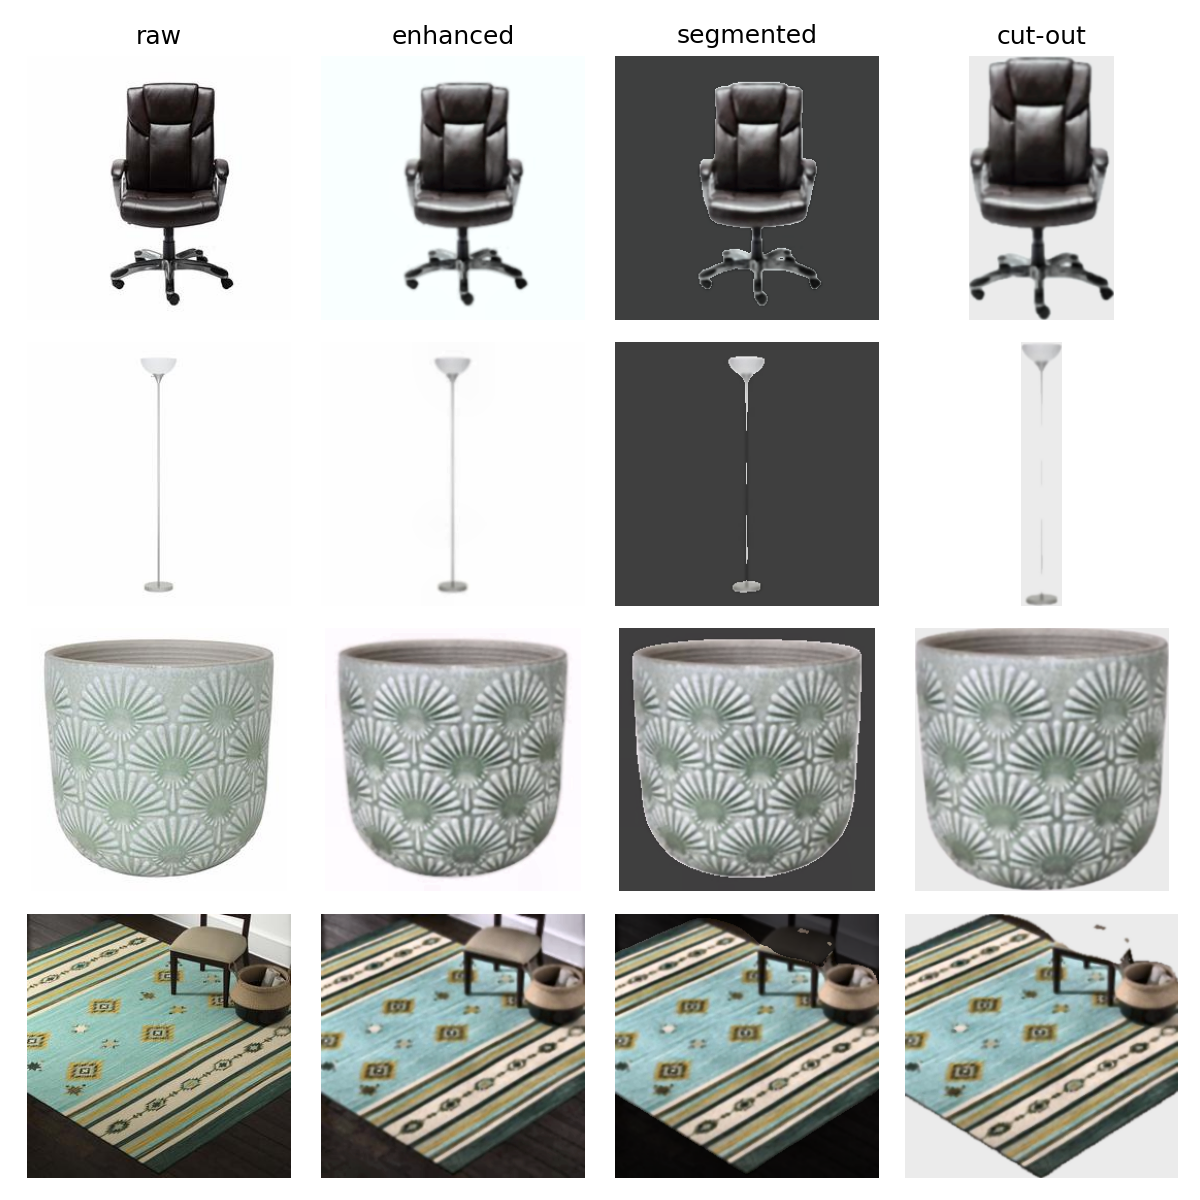

fig2_masks_iou.png


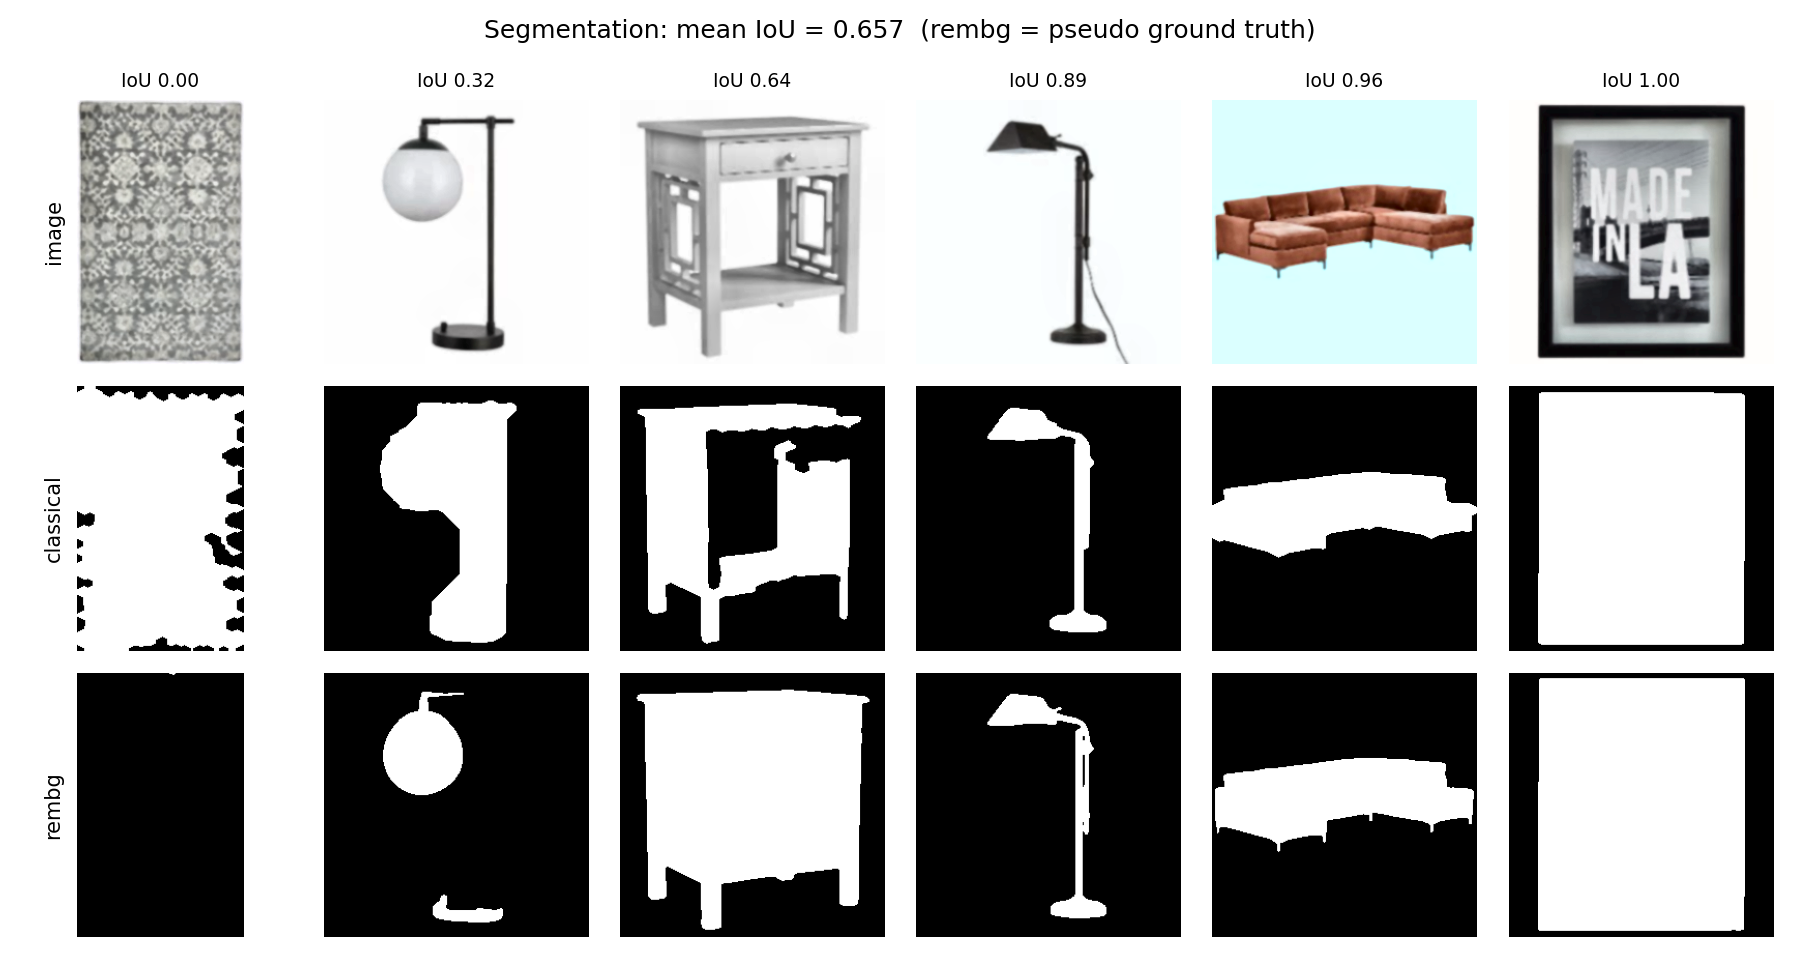

fig3_ndcg.png


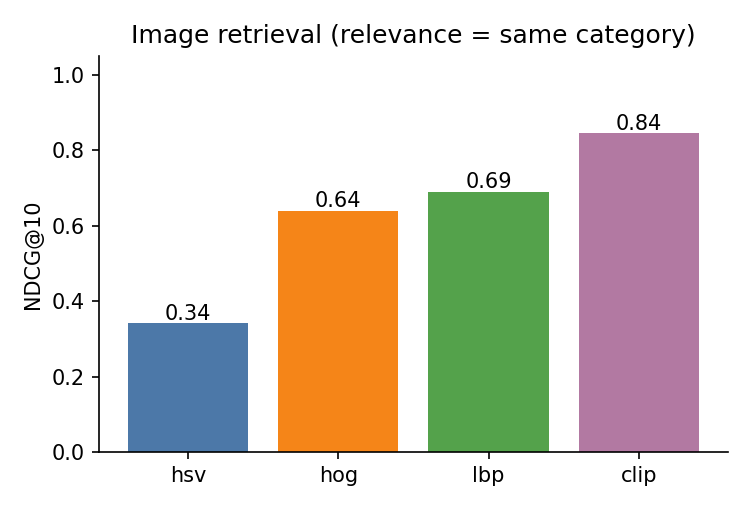

In [13]:
from IPython.display import Image, display
for f in sorted(os.listdir("results/figures")):
    print(f); display(Image("results/figures/" + f, width=800))

## 6. Quick scene demo with the real artifacts

In [21]:
# Run demo scene composer
# (Note: This relies on 'artifacts/palettes.npz' being created by the previous palette extraction step)
import os
if not os.path.exists("artifacts/palettes.npz"):
    print("Error: 'artifacts/palettes.npz' is missing. Please ensure you have patched and successfully run the palette extraction step (cell xjc09aLNi9P5) first!")
else:
    from src.compose import Library, compose
    from src.features import load_clip
    import src.features

    # Load the CLIP model tuple (model, preprocess, tokenizer)
    clip_model = load_clip(dev)
    # Explicitly ensure the model is on the correct GPU/CPU device to avoid runtime mismatch errors
    clip_model[0].to(dev)

    # Monkey-patch src.features.clip_text to always target our active device 'dev'
    orig_clip_text = src.features.clip_text
    src.features.clip_text = lambda texts, clip, device=dev: orig_clip_text(texts, clip, device=device)

    lib = Library("artifacts", clip_model)
    r = compose(lib, "cozy reading corner", harmony=True)
    print(r["scene"], r["style"], "harmony", round(r["harmony"], 3), f'{r["seconds"]:.2f}s')
    r["image"]

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


reading corner cozy harmony 0.95 1.06s


## 7. Package: size check + download (copy `artifacts/` and `results/` into your repo / Space)

In [22]:
# Package artifacts and results
!du -sh artifacts/cutouts artifacts/*.npy artifacts/*.npz
!zip -rq outputs.zip artifacts results -x "artifacts/masks/*"
!ls -lh outputs.zip
try:
    from google.colab import files
    files.download("outputs.zip")
except ImportError:
    print("Kaggle: outputs.zip is in the Output panel (right side) after 'Save Version'.")

16M	artifacts/cutouts
3.0M	artifacts/embeddings.npy
11M	artifacts/feat_hog.npy
764K	artifacts/feat_hsv.npy
952K	artifacts/feat_lbp.npy
72K	artifacts/palettes.npz
-rw-r--r-- 1 root root 24M Nov  9 09:52 outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>